In [1]:
import subprocess
subprocess.run(['pip', 'install', 'rasterio', 'matplotlib', 'numpy'], 
               capture_output=True)
print("Pronto!")

Pronto!


In [3]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Percorso al file TCI
tci_path = r"C:\Users\andre\OneDrive\Desktop\PARAMETRIC DESIGN\S2A_MSIL2A_20240817T105031_N0511_R051_T31UFT_20240817T143149.SAFE\GRANULE\L2A_T31UFT_A047810_20240817T105025\IMG_DATA\R10m\T31UFT_20240817T105031_TCI_10m.jp2"

with rasterio.open(tci_path) as src:
    print(f"Dimensioni: {src.width} x {src.height} pixel")
    print(f"Numero bande: {src.count}")
    print(f"CRS: {src.crs}")
    print(f"Risoluzione: {src.res} metri")
    
    # Leggiamo l'immagine
    tci = src.read()

print(f"Shape array: {tci.shape}")

Dimensioni: 10980 x 10980 pixel
Numero bande: 3
CRS: EPSG:32631
Risoluzione: (10.0, 10.0) metri
Shape array: (3, 10980, 10980)


In [4]:
# Ritaglia su Amsterdam — leggiamo solo una finestra
# Amsterdam è circa al centro-nord della tile
with rasterio.open(tci_path) as src:
    # Definiamo i bounds di Amsterdam in EPSG:32631
    # xmin, ymin, xmax, ymax
    from rasterio.windows import from_bounds
    
    window = from_bounds(
        left=109000, bottom=5797000,
        right=135000, top=5820000,
        transform=src.transform
    )
    
    tci_amsterdam = src.read(window=window)
    
print(f"Immagine ritagliata: {tci_amsterdam.shape}")
print(f"Dimensioni: {tci_amsterdam.shape[2]} x {tci_amsterdam.shape[1]} pixel")

Immagine ritagliata: (3, 302, 0)
Dimensioni: 0 x 302 pixel


In [5]:
with rasterio.open(tci_path) as src:
    print(f"Bounds della tile: {src.bounds}")
    print(f"CRS: {src.crs}")

Bounds della tile: BoundingBox(left=600000.0, bottom=5690220.0, right=709800.0, top=5800020.0)
CRS: EPSG:32631


In [6]:
with rasterio.open(tci_path) as src:
    from rasterio.windows import from_bounds
    
    window = from_bounds(
        left=630000, bottom=5775000,
        right=690000, top=5800000,
        transform=src.transform
    )
    
    tci_amsterdam = src.read(window=window)
    
print(f"Immagine ritagliata: {tci_amsterdam.shape}")
print(f"Dimensioni: {tci_amsterdam.shape[2]} x {tci_amsterdam.shape[1]} pixel")

Immagine ritagliata: (3, 2500, 6000)
Dimensioni: 6000 x 2500 pixel


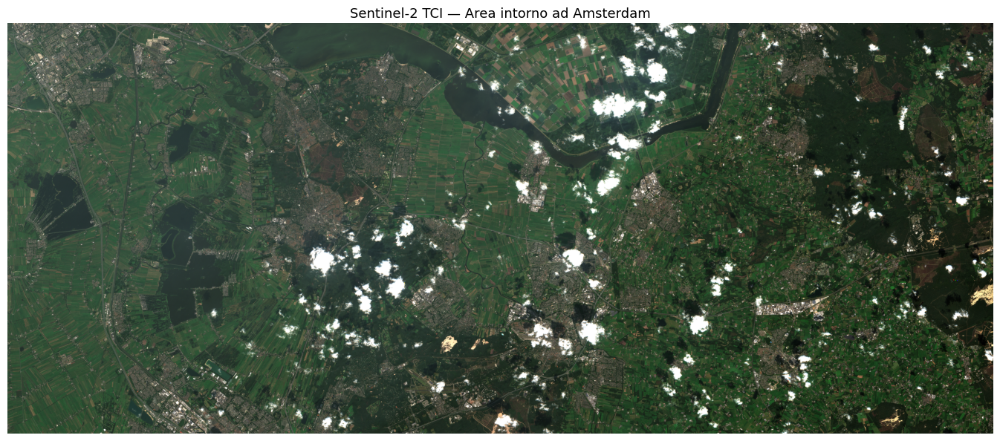

In [7]:
fig, ax = plt.subplots(figsize=(14, 6))

# Sentinel-2 TCI ha valori 0-255
img = np.transpose(tci_amsterdam, (1, 2, 0))

ax.imshow(img)
ax.set_title('Sentinel-2 TCI — Area intorno ad Amsterdam', fontsize=13)
ax.set_axis_off()
plt.tight_layout()
plt.savefig('sentinel2_amsterdam.png', dpi=100, bbox_inches='tight')
plt.show()

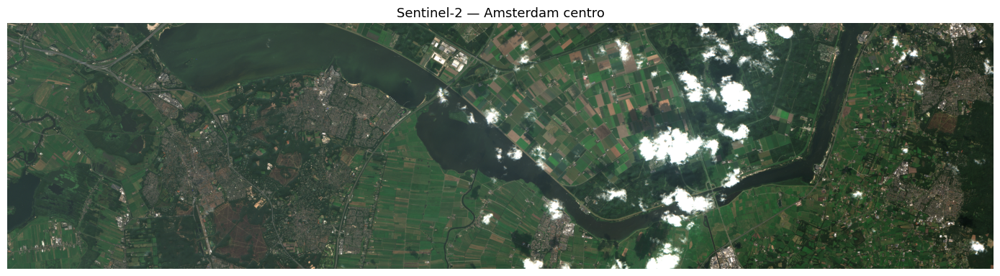

In [8]:
with rasterio.open(tci_path) as src:
    from rasterio.windows import from_bounds
    
    window = from_bounds(
        left=640000, bottom=5790000,
        right=680000, top=5800000,
        transform=src.transform
    )
    
    tci_amsterdam = src.read(window=window)

fig, ax = plt.subplots(figsize=(14, 8))
img = np.transpose(tci_amsterdam, (1, 2, 0))
ax.imshow(img)
ax.set_title('Sentinel-2 — Amsterdam centro', fontsize=13)
ax.set_axis_off()
plt.tight_layout()
plt.savefig('sentinel2_amsterdam2.png', dpi=100, bbox_inches='tight')
plt.show()

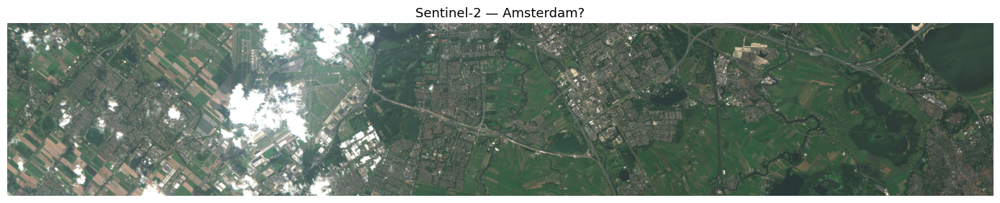

In [11]:
with rasterio.open(tci_path) as src:
    from rasterio.windows import from_bounds
    
    window = from_bounds(
        left=609000, bottom=5793000,
        right=649000, top=5803000,
        transform=src.transform
    )
    
    tci_amsterdam = src.read(window=window)

fig, ax = plt.subplots(figsize=(14, 8))
img = np.transpose(tci_amsterdam, (1, 2, 0))
ax.imshow(img)
ax.set_title('Sentinel-2 — Amsterdam?', fontsize=13)
ax.set_axis_off()
plt.tight_layout()
plt.savefig('sentinel2_amsterdam3.png', dpi=100, bbox_inches='tight')
plt.show()

In [13]:
tci_path_u = r"C:\Users\andre\OneDrive\Desktop\PARAMETRIC DESIGN\S2A_MSIL1C_20240817T105031_N0511_R051_T31UFU_20240817T125303.SAFE\GRANULE\L1C_T31UFU_A047810_20240817T105025\IMG_DATA\T31UFU_20240817T105031_TCI.jp2"

with rasterio.open(tci_path_u) as src:
    print(f"Dimensioni: {src.width} x {src.height} pixel")
    print(f"Bounds: {src.bounds}")
    print(f"CRS: {src.crs}")

Dimensioni: 10980 x 10980 pixel
Bounds: BoundingBox(left=600000.0, bottom=5790240.0, right=709800.0, top=5900040.0)
CRS: EPSG:32631


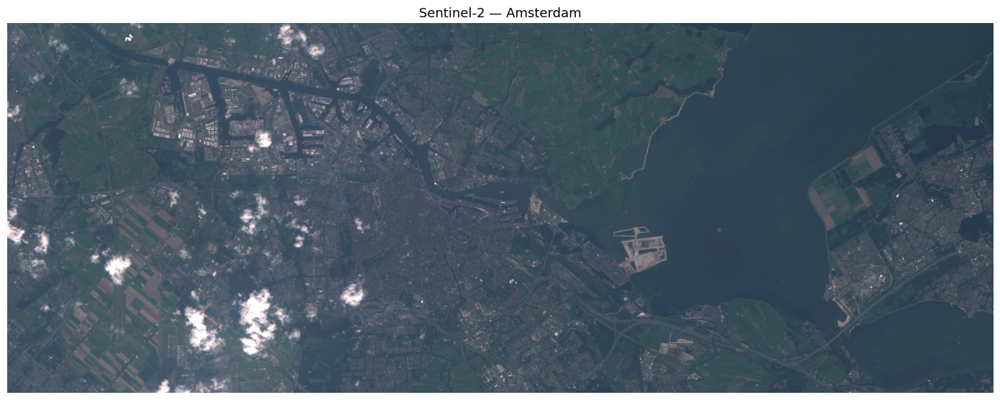

In [14]:
with rasterio.open(tci_path_u) as src:
    from rasterio.windows import from_bounds
    
    window = from_bounds(
        left=612000, bottom=5797000,
        right=652000, top=5812000,
        transform=src.transform
    )
    
    tci_ams = src.read(window=window)

fig, ax = plt.subplots(figsize=(14, 8))
img = np.transpose(tci_ams, (1, 2, 0))
ax.imshow(img)
ax.set_title('Sentinel-2 — Amsterdam', fontsize=13)
ax.set_axis_off()
plt.tight_layout()
plt.savefig('sentinel2_amsterdam_centro.png', dpi=150, bbox_inches='tight')
plt.show()

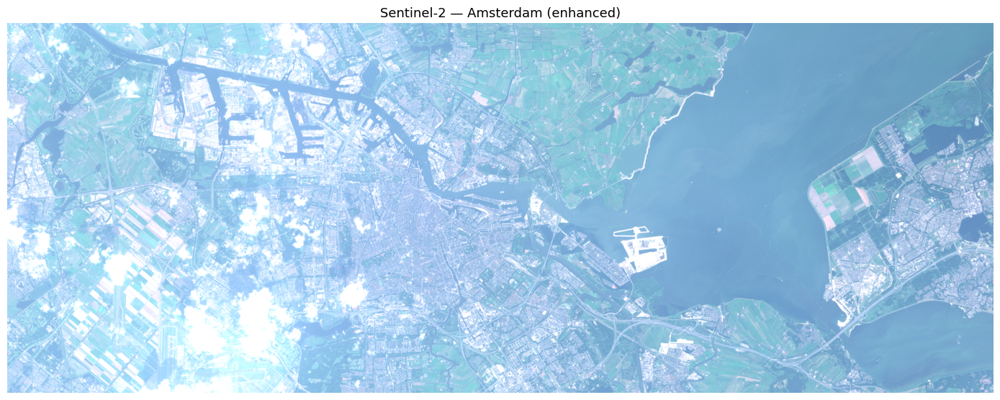

In [15]:
fig, ax = plt.subplots(figsize=(14, 8))

# Normalizziamo i valori per migliorare il contrasto
img = np.transpose(tci_ams, (1, 2, 0))
img_bright = np.clip(img * 2.5, 0, 255).astype(np.uint8)

ax.imshow(img_bright)
ax.set_title('Sentinel-2 — Amsterdam (enhanced)', fontsize=13)
ax.set_axis_off()
plt.tight_layout()
plt.savefig('sentinel2_amsterdam_bright.png', dpi=150, bbox_inches='tight')
plt.show()

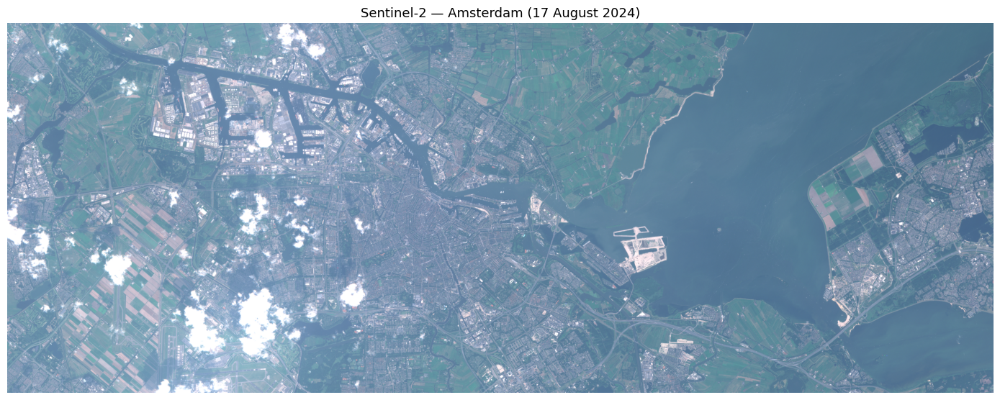

In [16]:
fig, ax = plt.subplots(figsize=(14, 8))

img = np.transpose(tci_ams, (1, 2, 0))
img_bright = np.clip(img * 1.8, 0, 255).astype(np.uint8)

ax.imshow(img_bright)
ax.set_title('Sentinel-2 — Amsterdam (17 August 2024)', fontsize=13)
ax.set_axis_off()
plt.tight_layout()
plt.savefig('sentinel2_amsterdam_final.png', dpi=150, bbox_inches='tight')
plt.show()

In [18]:
base_path = r"C:\Users\andre\OneDrive\Desktop\PARAMETRIC DESIGN\S2A_MSIL1C_20240817T105031_N0511_R051_T31UFU_20240817T125303.SAFE\GRANULE\L1C_T31UFU_A047810_20240817T105025\IMG_DATA"

b04_path = base_path + r"\T31UFU_20240817T105031_B04.jp2"
b08_path = base_path + r"\T31UFU_20240817T105031_B08.jp2"

with rasterio.open(b04_path) as src:
    from rasterio.windows import from_bounds
    window = from_bounds(612000, 5797000, 652000, 5812000, src.transform)
    red = src.read(1, window=window).astype(float)

with rasterio.open(b08_path) as src:
    nir = src.read(1, window=window).astype(float)

ndvi = (nir - red) / (nir + red + 1e-10)

print(f"NDVI calcolato!")
print(f"Valore minimo: {ndvi.min():.3f}")
print(f"Valore massimo: {ndvi.max():.3f}")
print(f"Media: {ndvi.mean():.3f}")

NDVI calcolato!
Valore minimo: -0.511
Valore massimo: 0.757
Media: 0.178


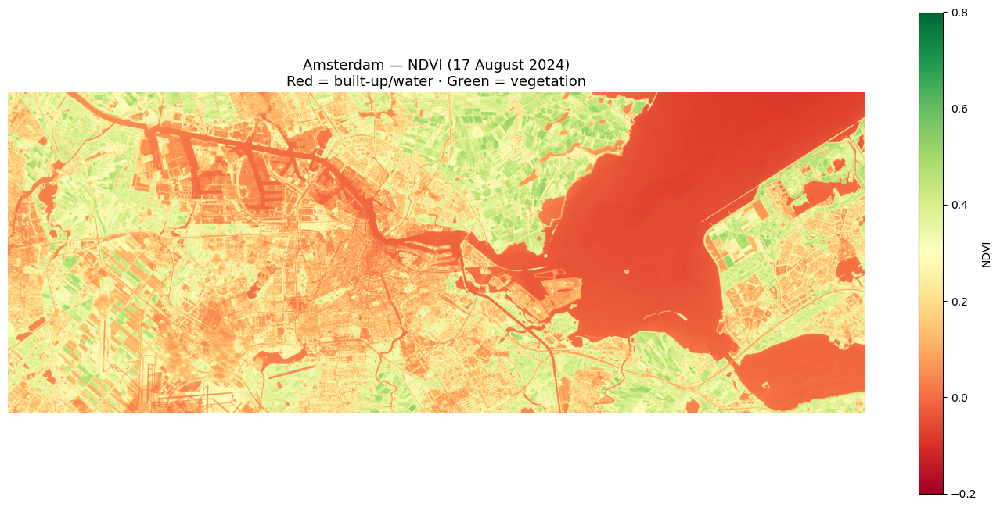

In [19]:
fig, ax = plt.subplots(figsize=(14, 8))

ndvi_plot = ax.imshow(
    ndvi,
    cmap='RdYlGn',
    vmin=-0.2,
    vmax=0.8
)

plt.colorbar(ndvi_plot, ax=ax, label='NDVI', shrink=0.8)
ax.set_title('Amsterdam — NDVI (17 August 2024)\nRed = built-up/water · Green = vegetation', fontsize=13)
ax.set_axis_off()
plt.tight_layout()
plt.savefig('amsterdam_ndvi.png', dpi=150, bbox_inches='tight')
plt.show()

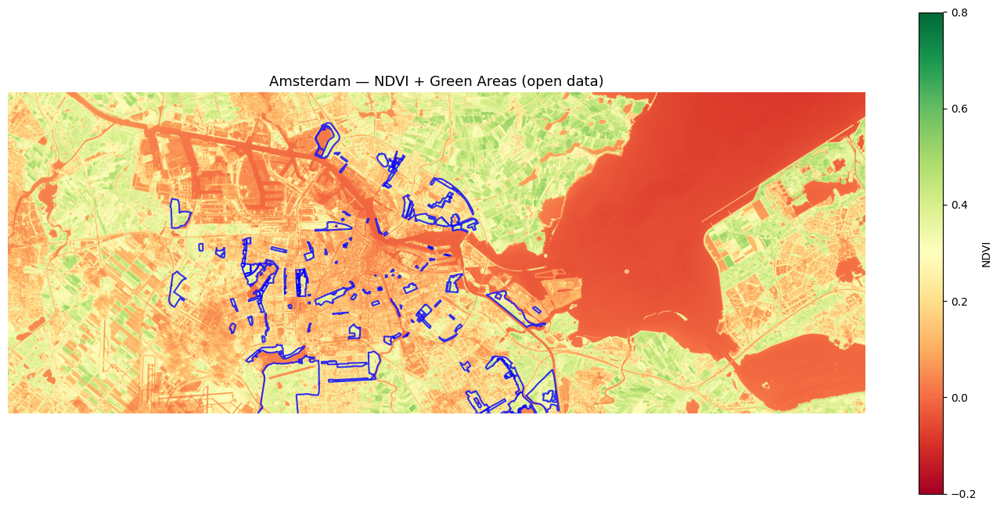

In [20]:
import geopandas as gpd
from rasterio.transform import from_bounds as fb

# Carichiamo i parchi
green = gpd.read_file(r"C:\Users\andre\OneDrive\Desktop\PARAMETRIC DESIGN\park_geojson_lnglat.json", 
                      on_invalid="ignore")

# Convertiamo in EPSG:32631 per allinearci al satellite
green_proj = green.to_crs("EPSG:32631")

# Bounds del nostro ritaglio
xmin, ymin, xmax, ymax = 612000, 5797000, 652000, 5812000

fig, ax = plt.subplots(figsize=(14, 8))

# NDVI come sfondo
ndvi_plot = ax.imshow(
    ndvi,
    cmap='RdYlGn',
    vmin=-0.2,
    vmax=0.8,
    extent=[xmin, xmax, ymin, ymax],
    aspect='auto'
)

# Parchi sovrapposti come contorni
green_proj.plot(
    ax=ax,
    facecolor='none',
    edgecolor='blue',
    linewidth=1.5,
    alpha=0.8
)

plt.colorbar(ndvi_plot, ax=ax, label='NDVI', shrink=0.8)
ax.set_title('Amsterdam — NDVI + Green Areas (open data)', fontsize=13)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_axis_off()
plt.tight_layout()
plt.savefig('amsterdam_ndvi_green.png', dpi=150, bbox_inches='tight')
plt.show()